In [4]:
import pandas as pd
import glob 


for f in glob.glob("data/*.csv"):
    df = pd.read_csv(f, sep=";", na_values="-", thousands=",")
    print("📄", f)
    print(df.columns.tolist())
    print(df.head(2), "\n")

📄 data\Day-ahead_prices_202411010000_202611020000_Hour.csv
['Start date', 'End date', 'Germany/Luxembourg [€/MWh] Calculated resolutions', '∅ DE/LU neighbours [€/MWh] Calculated resolutions', 'Belgium [€/MWh] Calculated resolutions', 'Denmark 1 [€/MWh] Calculated resolutions', 'Denmark 2 [€/MWh] Calculated resolutions', 'France [€/MWh] Calculated resolutions', 'Netherlands [€/MWh] Calculated resolutions', 'Norway 2 [€/MWh] Calculated resolutions', 'Austria [€/MWh] Calculated resolutions', 'Poland [€/MWh] Calculated resolutions', 'Sweden 4 [€/MWh] Calculated resolutions', 'Switzerland [€/MWh] Calculated resolutions', 'Czech Republic [€/MWh] Calculated resolutions', 'DE/AT/LU [€/MWh] Calculated resolutions', 'Northern Italy [€/MWh] Calculated resolutions', 'Slovenia [€/MWh] Calculated resolutions', 'Hungary [€/MWh] Calculated resolutions']
             Start date             End date  \
0  Nov 1, 2024 12:00 AM  Nov 1, 2024 1:00 AM   
1   Nov 1, 2024 1:00 AM  Nov 1, 2024 2:00 AM   

   Ge

In [6]:
def load(keyword):
    f = glob.glob(f"data/*{keyword}*.csv")[0]
    d = pd.read_csv(f, sep=";", na_values="-", thousands=",")
    d["time"] = pd.to_datetime(d["Start date"], format="%b %d, %Y %I:%M %p")
    return d.drop_duplicates("time").set_index("time")

def col(d, word):
    return d[[c for c in d.columns if word in c][0]]

price = load("Day-ahead")
gen   = load("generation")
cons  = load("consumption")

print("GEN:", gen.columns.tolist())
print("CONS:", cons.columns.tolist())

df = pd.DataFrame({
    "price": col(price, "Germany/Luxembourg"),
    "wind_on": col(gen, "Wind onshore"),
    "wind_off": col(gen, "Wind offshore"),
    "solar": col(gen, "Photovoltaics ["),
    "load": col(cons, "grid load"),
    "residual_load": col(cons, "Residual load"),
}).dropna()

print(df.shape)
df.head()
df["residual_load"] = df.load - df.wind_on - df.wind_off - df.solar
print(df.shape)
df.head()

GEN: ['Start date', 'End date', 'Total [MWh] Calculated resolutions', 'Photovoltaics and wind [MWh] Calculated resolutions', 'Wind offshore [MWh] Calculated resolutions', 'Wind onshore [MWh] Calculated resolutions', 'Photovoltaics [MWh] Calculated resolutions', 'Other [MWh] Calculated resolutions']
CONS: ['Start date', 'End date', 'grid load [MWh] Calculated resolutions', 'Residual load [MWh] Calculated resolutions']
(17542, 6)
(17542, 6)


,price,wind_on,wind_off,solar,load,residual_load
time,,,,,,
2024-11-01 00:00:00,63.34,16767.25,5267.50,0.0,43359.50,21324.75
2024-11-01 01:00:00,62.95,16532.25,5406.50,0.0,41816.25,19877.50
2024-11-01 02:00:00,57.10,16309.50,5368.00,0.0,40856.00,19178.50
2024-11-01 03:00:00,54.54,16056.00,5336.25,0.0,41017.50,19625.25
2024-11-01 04:00:00,56.99,15841.25,5338.75,0.0,42222.00,21042.00


In [8]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

# فیچرهای زمانی و قیمت‌های گذشته
df["hour"] = df.index.hour
df["weekday"] = df.index.weekday
df["month"] = df.index.month
df["price_lag_24"] = df.price.shift(24)    # قیمت دیروز همین ساعت
df["price_lag_168"] = df.price.shift(168)  # قیمت هفتهٔ قبل همین ساعت
data = df.dropna()

X = ["wind_on", "wind_off", "solar", "load", "residual_load",
     "hour", "weekday", "month", "price_lag_24", "price_lag_168"]

# تقسیم زمانی: ۳ ماه آخر برای تست
train = data[data.index < "2026-08-01"]
test  = data[data.index >= "2026-08-01"]

model = LGBMRegressor(n_estimators=500, learning_rate=0.05, verbose=-1)
model.fit(train[X], train.price)
test = test.assign(pred=model.predict(test[X]))

print("Baseline MAE (yesterday price) :", round(mean_absolute_error(test.price, test.price_lag_24), 2), "€/MWh")
print("Model MAE:", round(mean_absolute_error(test.price, test.pred), 2), "€/MWh")

C:\Users\Admin\AppData\Local\Temp\ipykernel_3424\1355870892.py:6: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["weekday"] = df.index.weekday


Baseline MAE (yesterday price) : 40.32 €/MWh
Model MAE: 53.82 €/MWh


Train MAE: 7.6
Corr residual_load ↔ price: 0.75
price_lag_24     2067
residual_load    2050
price_lag_168    1863
wind_off         1809
wind_on          1622
month            1537
load             1271
solar            1111
weekday           947
hour              723
dtype: int32


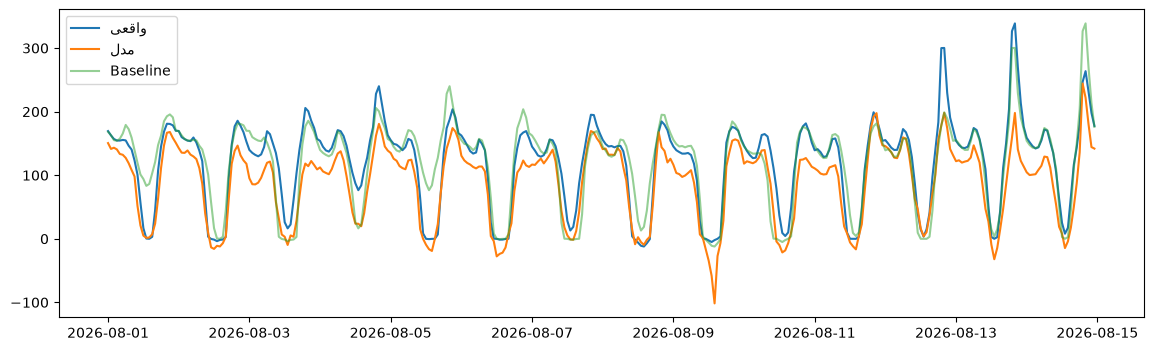

In [9]:
import matplotlib.pyplot as plt

# ۱. آیا مدل روی دادهٔ train خوب است؟
print("Train MAE:", round(mean_absolute_error(train.price, model.predict(train[X])), 2))

# ۲. رابطهٔ residual load با قیمت (باید مثبت و قوی باشد)
print("Corr residual_load ↔ price:", round(data.price.corr(data.residual_load), 2))

# ۳. مهم‌ترین فیچرها
print(pd.Series(model.feature_importances_, index=X).sort_values(ascending=False))

# ۴. نمودار دو هفته از دورهٔ تست
w = test.iloc[:336]
plt.figure(figsize=(14, 4))
plt.plot(w.index, w.price, label="واقعی")
plt.plot(w.index, w.pred, label="مدل")
plt.plot(w.index, w.price_lag_24, label="Baseline", alpha=0.5)
plt.legend(); plt.show()

In [10]:
# سطح قیمت = میانگین ۷ روز گذشته (فقط داده‌هایی که روز قبل معلوم است)
df["level_7d"] = df.price.shift(24).rolling(168).mean()
df["target"] = df.price - df.level_7d
data = df.dropna()

X2 = ["wind_on", "wind_off", "solar", "load", "residual_load",
      "hour", "weekday", "price_lag_24", "price_lag_168", "level_7d"]  # month حذف شد

train = data[data.index < "2026-08-01"]
test  = data[data.index >= "2026-08-01"]

model2 = LGBMRegressor(n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=50, verbose=-1)
model2.fit(train[X2], train.target)
test = test.assign(pred2=model2.predict(test[X2]) + test.level_7d)

print("Baseline MAE:", round(mean_absolute_error(test.price, test.price_lag_24), 2))
print("Model v1 MAE: 53.82")
print("Model v2 MAE:", round(mean_absolute_error(test.price, test.pred2), 2))

Baseline MAE: 40.32
Model v1 MAE: 53.82
Model v2 MAE: 46.45


In [11]:
# تغییر نسبت به دیروز همین ساعت
for c in ["wind_on", "wind_off", "solar", "load", "residual_load"]:
    df[f"d_{c}"] = df[c] - df[c].shift(24)

df["target3"] = df.price - df.price_lag_24   # تغییر قیمت نسبت به دیروز
data = df.dropna()

X3 = ["d_wind_on", "d_wind_off", "d_solar", "d_load", "d_residual_load",
      "residual_load", "hour", "weekday", "price_lag_24"]

train = data[data.index < "2026-08-01"]
test  = data[data.index >= "2026-08-01"]

model3 = LGBMRegressor(n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=50, verbose=-1)
model3.fit(train[X3], train.target3)
test = test.assign(pred3=model3.predict(test[X3]) + test.price_lag_24)

print("Baseline MAE:", round(mean_absolute_error(test.price, test.price_lag_24), 2))
print("Model v2 MAE: 46.45")
print("Model v3 MAE:", round(mean_absolute_error(test.price, test.pred3), 2))

Baseline MAE: 40.32
Model v2 MAE: 46.45
Model v3 MAE: 26.98


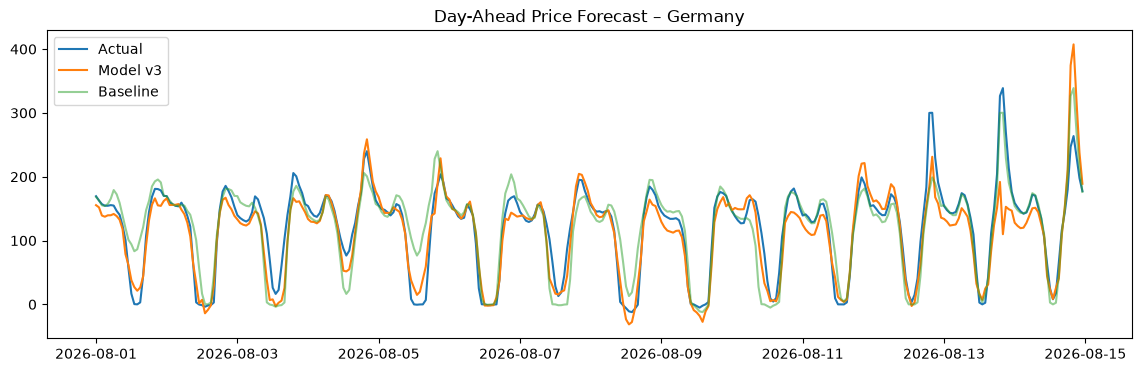

In [12]:
w = test.iloc[:336]
plt.figure(figsize=(14, 4))
plt.plot(w.index, w.price, label="Actual")
plt.plot(w.index, w.pred3, label="Model v3")
plt.plot(w.index, w.price_lag_24, label="Baseline", alpha=0.5)
plt.legend(); plt.title("Day-Ahead Price Forecast – Germany"); plt.show()